<a href="https://colab.research.google.com/github/timapasechnik/ml_basic/blob/main/HW9_Data_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

У цьому домашньому завданні ми будемо працювати з набором даних Tips. Нижче інформація про нього.

**Про датасет:**

Tips - це датасет, який містить інформацію про рахунки та чайові в ресторані.

**Колонки датасету:**
- `total_bill` - загальна сума рахунку (долари)
- `tip` - розмір чайових (долари)
- `sex` - стать відвідувача (Male/Female)
- `smoker` - чи курить (Yes/No)
- `day` - день тижня (Thur/Fri/Sat/Sun)
- `time` - час відвідування (Lunch/Dinner)
- `size` - розмір групи (кількість людей)

**Джерело:** Оригінальні дані зібрані в одному з американських ресторанів у 1990-х роках. Скачати і переглянути набір даних можна тут: https://www.kaggle.com/datasets/sakshisatre/tips-dataset

А також ми вже вивантажили файл з даними і завантажили вам у Матеріали до цього модуля.




**1. Гістограма розподілу рахунків**
Завантажте датасет Tips (Чайові) з файла у матеріалах `tips.csv`.
Створіть гістограму для колонки `total_bill` з 20 bins.
Опціонально можна додати підписи осей ОХ, ОУ, а також назву графіку.

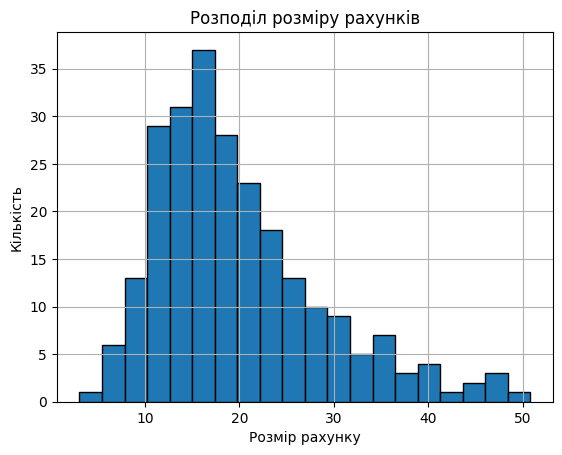

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

# Завантаження датасету Tips (Чайові) з CSV
df = pd.read_csv('tip.csv')
df.total_bill.hist(bins = 20, edgecolor='black');
plt.title('Розподіл розміру рахунків')
plt.xlabel('Розмір рахунку')
plt.ylabel('Кількість');

---

**2. Box plot чайових за днями тижня**

Створіть box plot, який показує розподіл чайових (`tip`) за днями тижня (`day`).
В який день навище медіанне значення чайоивх? Зелена горизонтальна лінія всередині кожного box-plot.


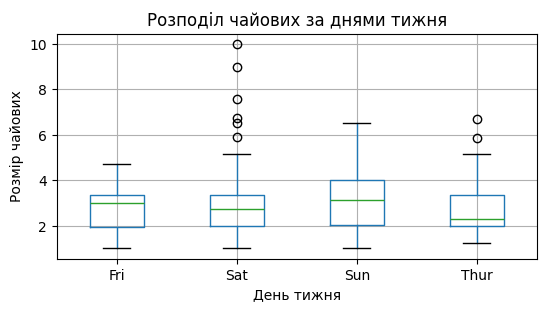


Найвище медіанне значення чайових $3.15 було у Sun


In [5]:
from numpy import median
df.boxplot(column='tip', by='day', figsize=(6, 3))
plt.title('Розподіл чайових за днями тижня')
plt.suptitle(' ')  # Прибирає автоматичний заголовок
plt.xlabel('День тижня')
plt.ylabel('Розмір чайових')
plt.show()

# медіанне значення чайових
median_tip = df.groupby('day')['tip'].median()
print(f"\nНайвище медіанне значення чайових ${median_tip.max():.2f} було у {median_tip.idxmax()}")

---

**3. Scatter plot: рахунок vs чайові**

Створіть діаграму розсіювання для `total_bill` та `tip`.

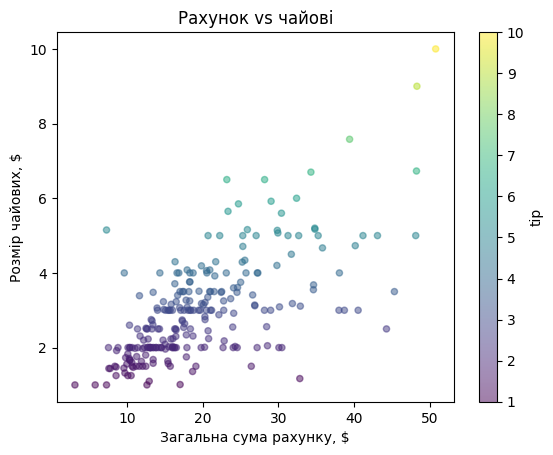

In [6]:
# Scatter plot - залежність рахунок vs чайові
df.plot.scatter(x='total_bill', y='tip', alpha=0.5, c='tip', colormap='viridis')
plt.title('Рахунок vs чайові')
plt.xlabel('Загальна сума рахунку, $')
plt.ylabel('Розмір чайових, $')
plt.show()

---

**4. Bar chart: середній рахунок за часом**

Створіть стовпчасту діаграму середнього рахунку за часом дня (`time`).

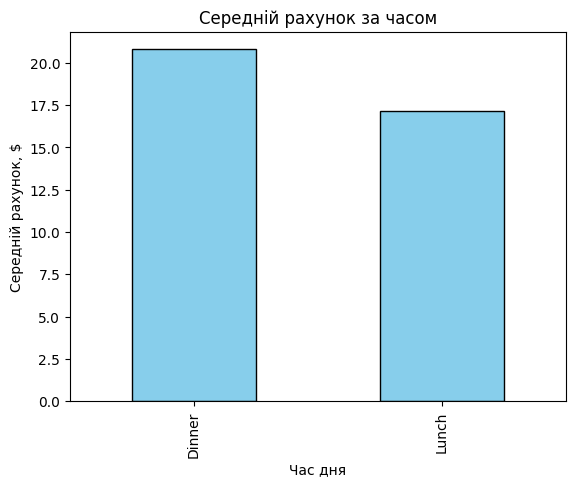

In [7]:
df.groupby('time')['total_bill'].mean().plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Середній рахунок за часом')
plt.xlabel('Час дня')
plt.ylabel('Середній рахунок, $')
plt.show()

---

**5. Інтерактивна діаграма розсіювання**

Створіть з допомогою бібліотек Plotly інтерактивний scatter plot для `total_bill` vs `tip` з кольором за статтю (`sex`).


In [15]:
import plotly.express as px
import plotly.graph_objects as go

graph = px.scatter(df, x='total_bill', y='tip', color='sex',
                 #hover_data=['sex', 'tip', ],
                 title='Повний рахунок vs чайові',
                 labels={'total_bill': 'Повний рахунок, $', 'tip': 'Чайові, $', 'sex': 'Стать', 'Female': 'Жінка', 'Male': 'Чоловік'},
                 color_continuous_scale='RdYlGn')
graph.show()

---

**6. Інтерактивний box plot: чайові за днями та статтю**

Створіть інтерактивний box plot для чайових за днями тижня з розбивкою за кольором по статі.

In [18]:
graph = px.box(df, x='day', y='tip', color='sex',
             title='Розподіл чайових за днями тижня та статтю',
             labels={'day': 'День тижня', 'tip': 'Розмір чайових, $', 'sex': 'Стать'})
graph.show()
